<a href="https://colab.research.google.com/github/jessicalewinter/deep-learning-specialization/blob/main/course-notebooks/neural-networks/Lab2_Forward_Pass.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratório 2 — MLP e o *forward pass* em NumPy

**Fundamentos de Redes Neurais Artificiais** · Aula 2

O roteiro acompanha a aula:

1. **O XOR com uma camada oculta**: a rede com pesos escolhidos à mão.
2. **Bloco 1 — Ativações**: as funções, as derivadas e a softmax estável.
3. **Bloco 2 — Perdas**: MSE, entropia cruzada binária e categórica.
4. **Bloco 3 — Inicialização**: os parâmetros de uma arquitetura qualquer.
5. **Bloco 4 — Forward pass**: o laço sobre as camadas, conferido com o exemplo 2-3-2 feito à mão.
6. **A rede nos dígitos**: os testes de sanidade de uma rede que calcula, mas ainda não aprendeu.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, VERMELHO, VERDE, TINTA = "#7C90B0", "#DB1E2F", "#2E8B8B", "#231F20"
print("pronto")

pronto


## 1. O XOR com uma camada oculta

Na Aula 1, o Perceptron não conseguiu aprender o XOR: nenhuma reta separa as duas classes.
Nos slides, resolvemos o problema com **três neurônios com degrau**, com pesos escolhidos à mão:

| Neurônio | Porta | Pesos | Bias |
|---|---|---|---|
| h₁ | OR | (1, 1) | −0,5 |
| h₂ | NAND | (−1, −1) | +1,5 |
| y | AND de h₁ e h₂ | (1, 1) | −1,5 |

Repare na notação: os pesos dos dois neurônios ocultos são as **colunas** de W1. Coluna é neurônio.

In [ ]:
def step(z):
    return np.where(z >= 0, 1, 0)

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)   # shape (4, 2)
y_xor = np.array([0, 1, 1, 0])

W1_xor = np.array([[ 1.0, -1.0],      # linha 1: pesos que saem de x1
                   [ 1.0, -1.0]])     # linha 2: pesos que saem de x2
b1_xor = np.array([[-0.5, 1.5]])      # um bias por neurônio oculto
w2_xor = np.array([[1.0], [1.0]])     # dois pesos chegando ao neurônio de saída
b2_xor = np.array([[-1.5]])

Z1 = X_xor @ W1_xor + b1_xor          # (4, 2) @ (2, 2) + (1, 2) = (4, 2)
H  = step(Z1)                         # a nova representação de cada ponto
z2 = H @ w2_xor + b2_xor              # (4, 2) @ (2, 1) + (1, 1) = (4, 1)
y_hat = step(z2).ravel()

print("  x        z1          h       z_saída   y   XOR")
for x, z, h, zo, yh, yv in zip(X_xor, Z1, H, z2.ravel(), y_hat, y_xor):
    print(f"{x}  {z}  {h}   {zo:+.1f}     {yh}    {yv}")
print("\nacertou todos?", np.array_equal(y_hat, y_xor))

  x        z1          h       z_saída   y   XOR
[0. 0.]  [-0.5  1.5]  [0 1]   -0.5     0    0
[0. 1.]  [0.5 0.5]  [1 1]   +0.5     1    1
[1. 0.]  [0.5 0.5]  [1 1]   +0.5     1    1
[1. 1.]  [ 1.5 -0.5]  [1 0]   -0.5     0    0

acertou todos? True


**O que observar.** As colunas `h` são a nova descrição de cada ponto. Os pontos (0, 1) e (1, 0) — os dois
da classe 1 — viram o **mesmo** ponto (1, 1) no espaço oculto. Por isso, lá, uma única reta basta.

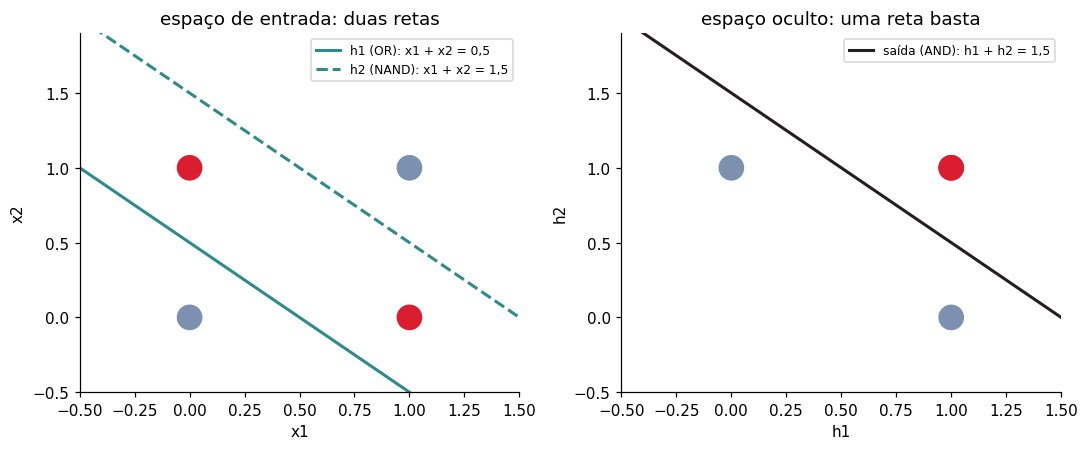

In [ ]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4.2))
xs = np.linspace(-0.5, 1.5, 2)

a1.plot(xs, 0.5 - xs, color=VERDE, lw=2, label="h1 (OR): x1 + x2 = 0,5")
a1.plot(xs, 1.5 - xs, color=VERDE, lw=2, ls="--", label="h2 (NAND): x1 + x2 = 1,5")
a1.scatter(*X_xor.T, c=[VERMELHO if c else AZUL for c in y_xor], s=250, zorder=3)
a1.set_title("espaço de entrada: duas retas"); a1.set_xlabel("x1"); a1.set_ylabel("x2")

a2.plot(xs, 1.5 - xs, color=TINTA, lw=2, label="saída (AND): h1 + h2 = 1,5")
a2.scatter(*H.T, c=[VERMELHO if c else AZUL for c in y_xor], s=250, zorder=3)
a2.set_title("espaço oculto: uma reta basta"); a2.set_xlabel("h1"); a2.set_ylabel("h2")

for ax in (a1, a2):
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.9); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## 2. Bloco 1 — Funções de ativação

O degrau não serve mais: sua derivada é zero onde existe, e o treino da Aula 3 depende de derivadas.
Guardamos cada ativação **junto com a sua derivada** num dicionário. Hoje o forward usa só a função;
na Aula 3, o backprop vai usar a derivada.

Repare na derivada da sigmoid: ela é calculada a partir da própria sigmoid, σ′ = σ·(1 − σ).

In [ ]:
def sigmoid(Z):
    return 1 / (1 + np.exp(-Z))

def relu(Z):
    return np.maximum(0, Z)

def leaky_relu(Z, alpha=0.01):
    return np.where(Z > 0, Z, alpha * Z)

ATIVACOES = {
    'sigmoid': (sigmoid,    lambda Z: sigmoid(Z) * (1 - sigmoid(Z))),
    'tanh':    (np.tanh,    lambda Z: 1 - np.tanh(Z) ** 2),
    'relu':    (relu,       lambda Z: (Z > 0).astype(float)),       # convenção: derivada 0 em Z = 0
    'leaky':   (leaky_relu, lambda Z: np.where(Z > 0, 1.0, 0.01)),
}

g, dg = ATIVACOES['relu']          # a função e a derivada
z = np.array([-2.0, -0.5, 0.0, 0.5, 2.0])
print("z        :", z)
print("ReLU(z)  :", g(z))
print("ReLU'(z) :", dg(z))

z        : [-2.  -0.5  0.   0.5  2. ]
ReLU(z)  : [0.  0.  0.  0.5 2. ]
ReLU'(z) : [0. 0. 0. 1. 1.]


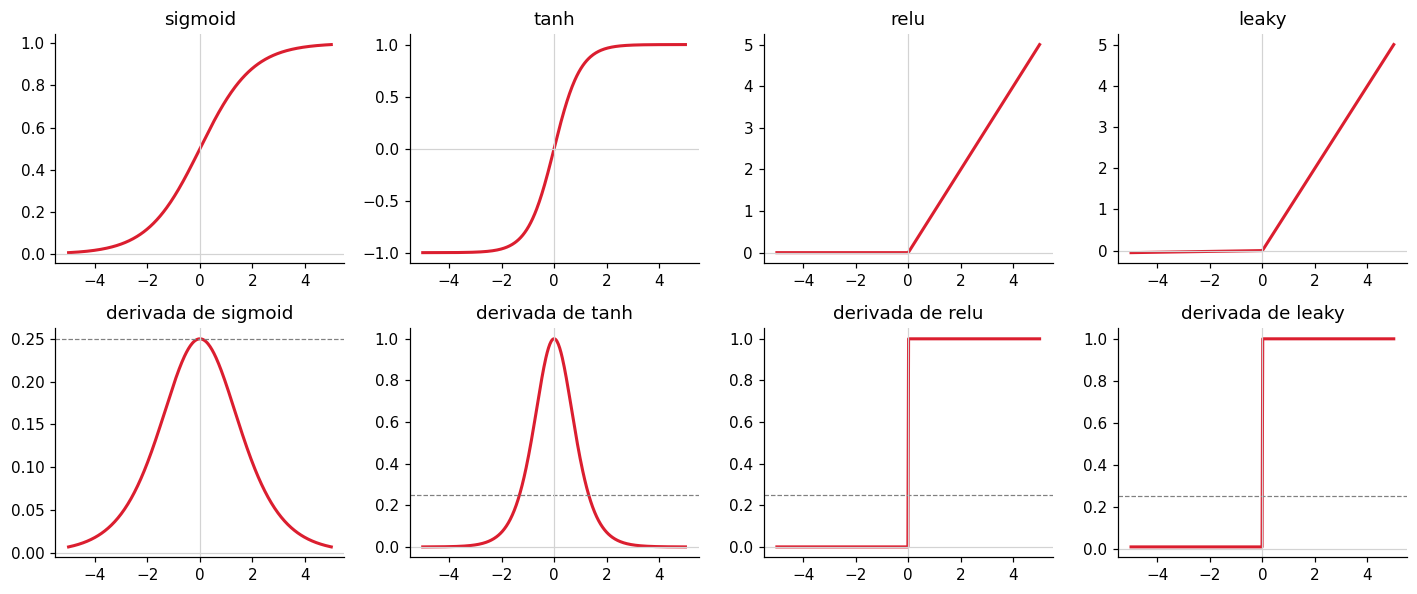

máximo de sigmoid'(z): 0.25   (em z = 0)
máximo de tanh'(z)   : 0.9998


In [ ]:
z = np.linspace(-5, 5, 400)
fig, axs = plt.subplots(2, 4, figsize=(13, 5.5))
for k, (nome, (f, df)) in enumerate(ATIVACOES.items()):
    axs[0, k].plot(z, f(z), color=VERMELHO, lw=2); axs[0, k].set_title(nome)
    axs[1, k].plot(z, df(z), color=VERMELHO, lw=2); axs[1, k].set_title(f"derivada de {nome}")
    axs[1, k].axhline(0.25, color="gray", ls="--", lw=0.8)
    for ax in axs[:, k]:
        ax.axhline(0, color="lightgray", lw=0.8); ax.axvline(0, color="lightgray", lw=0.8)
plt.tight_layout(); plt.show()

print("máximo de sigmoid'(z):", ATIVACOES['sigmoid'][1](z).max().round(4), "  (em z = 0)")
print("máximo de tanh'(z)   :", ATIVACOES['tanh'][1](z).max().round(4))

### Por que a não linearidade é essencial

Sem ativação, duas camadas calculam (X W1) W2. Como o produto de matrizes é associativo, isso é X (W1 W2):
**uma única camada linear**. A célula abaixo confere numericamente.

In [ ]:
rng = np.random.default_rng(0)
X  = rng.normal(size=(5, 4))
W1 = rng.normal(size=(4, 8))
W2 = rng.normal(size=(8, 3))

duas_camadas = (X @ W1) @ W2
uma_camada   = X @ (W1 @ W2)          # W' = W1 W2 tem shape (4, 3)
print("as duas são iguais?", np.allclose(duas_camadas, uma_camada))

com_relu = relu(X @ W1) @ W2
print("e com ReLU no meio?", np.allclose(com_relu, uma_camada))

as duas são iguais? True
e com ReLU no meio? False


### O preço da sigmoid: um fator de 0,25 por camada

No melhor caso, cada camada com sigmoid multiplica o sinal do gradiente por 0,25 (o máximo de σ′).
Com ReLU, o fator é 1 nos neurônios ativos.

In [ ]:
print("camadas   sigmoid (0,25^L)   ReLU ativa (1^L)")
for L in [1, 2, 3, 5, 10]:
    print(f"{L:>5}      {0.25 ** L:>12.7f}          {1.0 ** L:.0f}")

camadas   sigmoid (0,25^L)   ReLU ativa (1^L)
    1         0.2500000          1
    2         0.0625000          1
    3         0.0156250          1
    5         0.0009766          1
   10         0.0000010          1


### Saturação

Para |z| grande, a sigmoid fica praticamente constante e a derivada praticamente zero.

In [ ]:
dsig = ATIVACOES['sigmoid'][1]
for zz in [0, 2, 4, 6, 10]:
    print(f"z = {zz:>2}:  sigmoid = {sigmoid(zz):.5f}   sigmoid' = {dsig(zz):.6f}")

z =  0:  sigmoid = 0.50000   sigmoid' = 0.250000
z =  2:  sigmoid = 0.88080   sigmoid' = 0.104994
z =  4:  sigmoid = 0.98201   sigmoid' = 0.017663
z =  6:  sigmoid = 0.99753   sigmoid' = 0.002467
z = 10:  sigmoid = 0.99995   sigmoid' = 0.000045


### A softmax estável

A softmax transforma os logits de cada amostra (cada **linha**) numa distribuição de probabilidade.
Com logits grandes, `np.exp` estoura. Subtrair o máximo de cada linha não muda o resultado e elimina o problema.

Atenção ao `keepdims=True`: sem ele, o máximo e a soma viram vetores de shape `(m,)` e o broadcasting
divide na direção errada.

In [ ]:
def softmax_ingenua(Z):
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

def softmax(Z):
    Z = Z - Z.max(axis=1, keepdims=True)       # estabilidade: o maior logit vira 0
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)    # cada linha soma 1

Z = np.array([[2.1, 0.4, -1.2, 3.3, 0.1],      # o exemplo dos slides
              [1000.0, 1001.0, 1002.0, 0.0, 0.0]])

with np.errstate(over="ignore", invalid="ignore"):
    print("ingênua:\n", softmax_ingenua(Z))
print("estável:\n", softmax(Z))
print("soma de cada linha:", softmax(Z).sum(axis=1))

ingênua:
 [[0.2139 0.0391 0.0079 0.7102 0.0289]
 [   nan    nan    nan 0.     0.    ]]
estável:
 [[0.2139 0.0391 0.0079 0.7102 0.0289]
 [0.09   0.2447 0.6652 0.     0.    ]]
soma de cada linha: [1. 1.]


In [ ]:
# com duas classes, a softmax é a sigmoid da diferença dos logits
z2 = np.array([[-2.5, 0.5]])
print("softmax, classe 1     :", softmax(z2)[0, 1])
print("sigmoid(z1 - z0)      :", sigmoid(0.5 - (-2.5)))

softmax, classe 1     : 0.9525741268224334
sigmoid(z1 - z0)      : 0.9525741268224334


## 3. Bloco 2 — Funções de perda

O `clip` evita `log(0)`, que devolveria −infinito e contaminaria todo o cálculo.
Na entropia cruzada categórica, `Y` está em **one-hot**, com shape `(m, k)`.

In [ ]:
def mse(Y, Y_hat):
    return np.mean((Y - Y_hat) ** 2)

def bce(Y, Y_hat, eps=1e-12):
    Y_hat = np.clip(Y_hat, eps, 1 - eps)
    return -np.mean(Y * np.log(Y_hat) + (1 - Y) * np.log(1 - Y_hat))

def cce(Y, Y_hat, eps=1e-12):                  # Y em one-hot, shape (m, k)
    Y_hat = np.clip(Y_hat, eps, 1.0)
    return -np.mean(np.sum(Y * np.log(Y_hat), axis=1))

def one_hot(y, k):
    Y = np.zeros((len(y), k))
    Y[np.arange(len(y)), y] = 1
    return Y

print(one_hot(np.array([0, 2, 1]), 3))

[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]]


### Conferindo com os exemplos dos slides

In [ ]:
# MSE: erros 0,5, -1 e 0  ->  média dos quadrados = 0,417
y    = np.array([[3.0], [-1.0], [2.0]])
yhat = np.array([[2.5], [ 0.0], [2.0]])
print("MSE:", round(mse(y, yhat), 4))

# BCE com rótulo 1: errar com confiança custa caro
for p in [0.9, 0.5, 0.1, 0.01]:
    print(f"BCE com y = 1 e ŷ = {p:<4}:  {bce(np.array([[1.0]]), np.array([[p]])):.3f}")

# CCE: só sobrevive o termo da classe correta
y_hat = np.array([[0.7, 0.2, 0.1]])
for classe in range(3):
    print(f"CCE com classe correta {classe}:  {cce(one_hot(np.array([classe]), 3), y_hat):.3f}")

MSE: 0.4167
BCE com y = 1 e ŷ = 0.9 :  0.105
BCE com y = 1 e ŷ = 0.5 :  0.693
BCE com y = 1 e ŷ = 0.1 :  2.303
BCE com y = 1 e ŷ = 0.01:  4.605
CCE com classe correta 0:  0.357
CCE com classe correta 1:  1.609
CCE com classe correta 2:  2.303


### O bug mais traiçoeiro: `(m,)` contra `(m, 1)`

Subtrair um vetor de shape `(5,)` de uma matriz `(5, 1)` **não dá erro**: o broadcasting produz uma matriz `(5, 5)`.
A perda sai errada, em silêncio.

In [ ]:
y_vetor  = np.array([1.0, 0.0, 1.0, 1.0, 0.0])            # shape (5,)
y_coluna = np.array([[0.9], [0.2], [0.8], [0.6], [0.1]])  # shape (5, 1)

diferenca = y_vetor - y_coluna
print("shape da diferença:", diferenca.shape, " <- 25 números em vez de 5!")
print("MSE errado :", round(mse(y_vetor, y_coluna), 4))
print("MSE correto:", round(mse(y_vetor.reshape(-1, 1), y_coluna), 4))

shape da diferença: (5, 5)  <- 25 números em vez de 5!
MSE errado : 0.348
MSE correto: 0.052


## 4. Bloco 3 — Inicialização dos parâmetros

A arquitetura é uma lista. `[64, 32, 10]` significa 64 entradas, uma camada oculta com 32 neurônios e 10 saídas.

Para cada camada, `W` tem shape **(entradas, saídas)** e `b` tem shape `(1, saídas)`.
Os pesos começam **aleatórios** (para que os neurônios não fiquem idênticos) e **pequenos** (para não saturar).

In [ ]:
def inicializa(camadas, escala=0.01, seed=0):
    rng = np.random.default_rng(seed)
    params = {}
    for l in range(1, len(camadas)):
        params[f'W{l}'] = rng.normal(0, escala, (camadas[l-1], camadas[l]))
        params[f'b{l}'] = np.zeros((1, camadas[l]))
    return params

def conta_parametros(params):
    return sum(p.size for p in params.values())

params = inicializa([64, 32, 10])
for nome, p in params.items():
    print(f"{nome}: shape {p.shape}  ->  {p.size} números")
print("total de parâmetros:", conta_parametros(params))     # 2410, como no quiz

W1: shape (64, 32)  ->  2048 números
b1: shape (1, 32)  ->  32 números
W2: shape (32, 10)  ->  320 números
b2: shape (1, 10)  ->  10 números
total de parâmetros: 2410


### Por que não começar com todos os pesos iguais?

---



Se todos os neurônios de uma camada começam com os mesmos pesos, todos calculam a mesma coisa —
e, na Aula 3, vão receber as mesmas correções. A camada inteira se comporta como um único neurônio.

In [ ]:
X_teste = np.random.default_rng(1).normal(size=(3, 4))
W_igual = np.full((4, 5), 0.1)                 # 5 neurônios, todos com os mesmos pesos
print("saídas dos 5 neurônios (uma linha por amostra):")
print(relu(X_teste @ W_igual))

saídas dos 5 neurônios (uma linha por amostra):
[[0.0194 0.0194 0.0194 0.0194 0.0194]
 [0.1396 0.1396 0.1396 0.1396 0.1396]
 [0.1234 0.1234 0.1234 0.1234 0.1234]]


## 5. Bloco 4 — O *forward pass*

Duas equações por camada, para cada camada oculta l:

  Z⁽ˡ⁾ = A⁽ˡ⁻¹⁾ W⁽ˡ⁾ + b⁽ˡ⁾        A⁽ˡ⁾ = g(Z⁽ˡ⁾)

com A⁽⁰⁾ = X. A camada de saída fica fora do laço porque usa softmax.
O **cache** guarda todos os Z e A: o backprop da Aula 3 vai precisar deles.

In [ ]:
def forward(X, params, ativacao='relu'):
    g, _ = ATIVACOES[ativacao]          # a função g; a derivada fica para a Aula 3
    L = len(params) // 2                # número de camadas com pesos
    cache = {'A0': X}
    A = X

    for l in range(1, L):               # camadas ocultas
        Z = A @ params[f'W{l}'] + params[f'b{l}']
        A = g(Z)
        cache[f'Z{l}'], cache[f'A{l}'] = Z, A

    ZL = A @ params[f'W{L}'] + params[f'b{L}']   # camada de saída
    AL = softmax(ZL)
    cache[f'Z{L}'], cache[f'A{L}'] = ZL, AL
    return AL, cache

### Primeiro teste: o exemplo 2-3-2 feito à mão

Montamos o dicionário de parâmetros com os números dos slides e conferimos cada etapa.
Se o código não reproduzir **0,0474** e **3,0486**, o erro está no código: a conta à mão foi conferida.

In [ ]:
x = np.array([[1.0, -2.0]])
params_mao = {
    'W1': np.array([[ 0.50, -1.00,  0.25],
                    [-0.50,  0.50, -1.00]]),
    'b1': np.array([[ 0.00,  0.50, -0.25]]),
    'W2': np.array([[ 1.00, -1.00],
                    [ 0.50,  0.50],
                    [-2.00,  1.00]]),
    'b2': np.array([[ 0.00,  0.00]]),
}
print("parâmetros:", conta_parametros(params_mao))           # 17

A2, cache = forward(x, params_mao, 'relu')
print("Z1 =", cache['Z1'])        # [ 1.5 -1.5  2. ]
print("A1 =", cache['A1'])        # [ 1.5  0.   2. ]
print("Z2 =", cache['Z2'])        # [-2.5  0.5]
print("A2 =", A2)                 # [0.0474 0.9526]

Y_mao = one_hot(np.array([0]), 2)                             # rótulo: classe 0
print("perda com rótulo 0:", round(cce(Y_mao, A2), 4))         # 3.0486
print("perda com rótulo 1:", round(cce(one_hot(np.array([1]), 2), A2), 4))   # 0.0486

assert np.allclose(A2, [[0.0474, 0.9526]], atol=1e-4)
assert np.isclose(cce(Y_mao, A2), 3.0486, atol=1e-4)
print("\nexemplo à mão reproduzido")

parâmetros: 17
Z1 = [[ 1.5 -1.5  2. ]]
A1 = [[1.5 0.  2. ]]
Z2 = [[-2.5  0.5]]
A2 = [[0.0474 0.9526]]
perda com rótulo 0: 3.0486
perda com rótulo 1: 0.0486

exemplo à mão reproduzido


### Análise de dimensões

Antes de usar a rede em dados reais, conferimos o shape de tudo o que está no cache.

In [ ]:
m = 7
X_falso = np.random.default_rng(2).normal(size=(m, 64))
AL, cache = forward(X_falso, inicializa([64, 32, 10]), 'relu')
for nome, valor in cache.items():
    print(f"{nome}: {valor.shape}")

A0: (7, 64)
Z1: (7, 32)
A1: (7, 32)
Z2: (7, 10)
A2: (7, 10)


## 6. A rede nos dígitos

O conjunto de dígitos do scikit-learn tem 1.797 imagens 8×8 em tons de cinza: 64 pixels por imagem,
10 classes. Dividimos os pixels por 16 para colocá-los entre 0 e 1.

X: (1797, 64)   y: (1797,)   Y: (1797, 10)


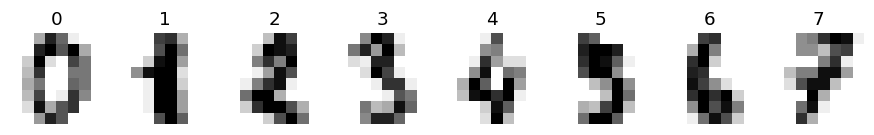

In [ ]:
from sklearn.datasets import load_digits

dados = load_digits()
X = dados.data / 16.0                 # shape (1797, 64), valores entre 0 e 1
y = dados.target                      # shape (1797,), classes 0 a 9
Y = one_hot(y, 10)                    # shape (1797, 10)
print("X:", X.shape, "  y:", y.shape, "  Y:", Y.shape)

fig, axs = plt.subplots(1, 8, figsize=(10, 1.6))
for ax, img, rot in zip(axs, dados.images, y):
    ax.imshow(img, cmap="gray_r"); ax.set_title(rot); ax.axis("off")
plt.show()

### Dois asserts que pegam quase todo erro

In [ ]:
params = inicializa([64, 32, 10])
AL, cache = forward(X, params, 'relu')

assert AL.shape == (X.shape[0], 10),    'dimensão da saída errada'
assert np.allclose(AL.sum(axis=1), 1),  'softmax não normalizou'
print("shape da saída:", AL.shape, " — os dois testes passaram")

shape da saída: (1797, 10)  — os dois testes passaram


### O que observar: uma rede que calcula, mas não sabe nada

Com pesos pequenos e nenhum treino, a softmax dá cerca de 1/10 para cada classe. Então:

- a perda deve ficar perto de **ln 10 ≈ 2,303**;
- a acurácia deve ficar perto de **10%**, como um chute.

In [ ]:
perda = cce(Y, AL)
acuracia = np.mean(AL.argmax(axis=1) == y)
print(f"perda inicial : {perda:.4f}    (ln 10 = {np.log(10):.4f})")
print(f"acurácia      : {acuracia:.1%}")
print("\nprobabilidades previstas para a primeira imagem:")
print(AL[0])

perda inicial : 2.3024    (ln 10 = 2.3026)
acurácia      : 12.0%

probabilidades previstas para a primeira imagem:
[0.1    0.0999 0.1    0.1    0.1    0.1001 0.1    0.1    0.1    0.1   ]


### A escala da inicialização importa

Com pesos grandes, os logits ficam grandes e a softmax fica "confiante" desde o início — sem ter aprendido nada.
A perda inicial se afasta de ln 10. É exatamente o que o teste de sanidade detecta, e é o assunto da Aula 4.

In [ ]:
print("escala    perda inicial    maior probabilidade média")
for escala in [0.01, 0.1, 1.0, 5.0]:
    AL_e, _ = forward(X, inicializa([64, 32, 10], escala=escala), 'relu')
    print(f"{escala:>6}    {cce(Y, AL_e):>12.3f}    {AL_e.max(axis=1).mean():>14.3f}")

escala    perda inicial    maior probabilidade média
  0.01           2.302             0.100
   0.1           2.291             0.115
   1.0          12.623             0.883
   5.0          24.059             0.997


### Saturação na prática

Com ativação sigmoid e pesos grandes, boa parte dos neurônios ocultos opera na região saturada,
onde a derivada é praticamente zero.

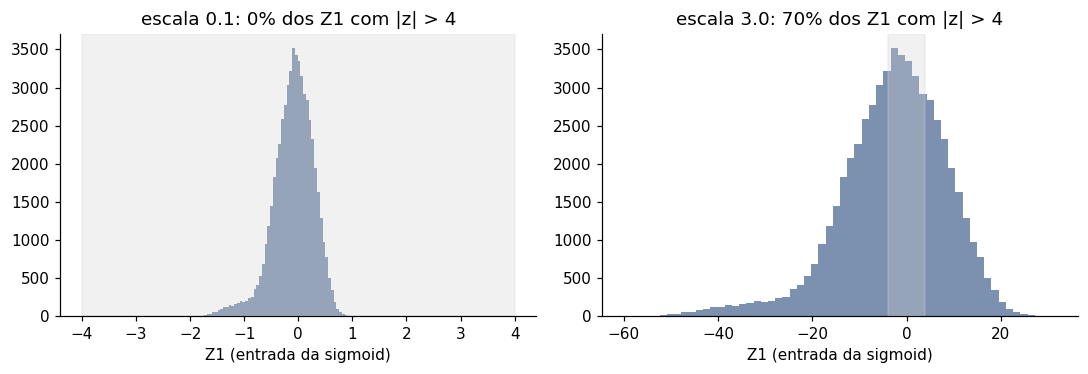

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, escala in zip(axs, [0.1, 3.0]):
    _, c = forward(X, inicializa([64, 32, 10], escala=escala), 'sigmoid')
    Z1 = c['Z1'].ravel()
    saturados = np.mean(np.abs(Z1) > 4)
    ax.hist(Z1, bins=60, color=AZUL)
    ax.axvspan(-4, 4, color="lightgray", alpha=0.3)
    ax.set_title(f"escala {escala}: {saturados:.0%} dos Z1 com |z| > 4")
    ax.set_xlabel("Z1 (entrada da sigmoid)")
plt.tight_layout(); plt.show()

---
## Resumo

- A camada oculta muda a representação dos dados; a saída é um classificador simples nesse novo espaço.
- O forward são duas equações por camada: `Z = A @ W + b` e `A = g(Z)`.
- `W` tem shape (entradas, saídas); conferir shapes é mais rápido que depurar.
- A softmax precisa ser estável e usar `keepdims=True`.
- Cada tarefa tem seu par saída-perda: linear + MSE, sigmoid + BCE, softmax + CCE.
- Antes de treinar: perda perto de ln k e acurácia perto de 1/k.

**Na Aula 3:** as derivadas guardadas em `ATIVACOES` e os valores guardados no `cache` serão usados pelo
*backpropagation* para calcular como a perda muda com cada peso — e a rede vai, finalmente, aprender.